In [101]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

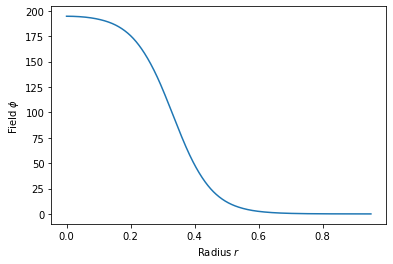

In [102]:
#Definition of the potential#
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
a = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
T = 93.
def V(phi): return 0.5*gamma*(T**2-T0**2)*phi**2-1/3*a*T*phi**3+0.25*lam*phi**4
def dV(phi): return gamma*(T**2-T0**2)*phi-a*T*phi**2+lam*phi**3

#critical bubble#
xi = np.array(range(25000))*0.01
Vmin = np.amin(V(xi))
vt = xi[np.where(V(xi) == Vmin)[0]][0]
profile = SingleFieldInstanton(vt, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()

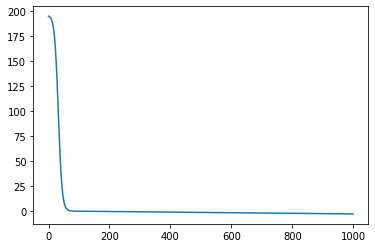

In [204]:
#initialization of the evolution#
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value = "extrapolate")
dr = 0.01
dt = 0.002
r = np.array(range(1,1001))*dr
phi = fphi(r)
phi2 = np.zeros(profile.Phi.size-1)
plt.plot(phi)

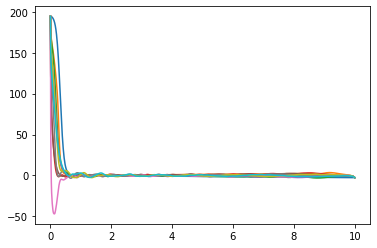

In [205]:
for i in range(10000):
    phi += (0.5 * dt * phi2)
    for j in range(1, phi2.size-1):
        phi2[j] = phi2[j] + dt*((phi[j+1]+phi[j-1]-2*phi[j])/(dr**2)+(phi[j+1]-phi[j-1])/(dr*r[j])-dV(phi[j]))
    phi += (0.5 * dt * phi2)
    if(i%1000==0):
        plt.plot(r,phi)
plt.show()